# Brillouin Scattering from Strain Pulses

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/06-optics/01-brillouin_scattering.ipynb)

In this example the broadband picosecond ultrasonics experiment of {cite:t}`bojahr2012` is simulated.
A metallic La$_{0.7}$Sr$_{0.3}$MnO$_3$ (LSMO) transducer on a SrTiO$_3$ (STO) substrate is excited by an intense laser pulse and launches a bipolar strain pulse into the transparent substrate.
The strain pulse modulates the refractive index of STO and partially reflects a white-light probe pulse, which interferes with the reflection from the surface.
The resulting oscillations of the transient reflectivity are known as Brillouin oscillations, since they correspond to the Brillouin backscattering of a photon by a longitudinal acoustic phonon with the wave vector

$$
k_\mathrm{P} = \frac{4 \pi}{\lambda} n(\lambda) \cos\beta
$$

for the probe wavelength $\lambda$, the refractive index $n(\lambda)$ of STO, and the internal angle $\beta$ of the probe light.

:::{admonition} Reference {cite}`bojahr2012`
:class: seealso
A. Bojahr, M. Herzog, D. Schick, I. Vrejoiu, and M. Bargheer, _Calibrated real-time detection of nonlinearly propagating strain waves_, [Phys. Rev. B 86, 144306 (2012)](https://doi.org/10.1103/PhysRevB.86.144306)
:::

:::{note}
The sample consists of more than 24000 layers, i.e. unit cells, so that the calculation of the strain pulses and the transient reflectivity for four fluences takes several minutes.
They are faster with the optional packages `numba` for the phonons and `dask` for the parallel calculation of the reflectivity, e.g. installed by `pip install udkm1Dsim[numba,parallel]`.
:::

For high strain amplitudes, the compressive and tensile parts of the strain pulse propagate faster and slower than the sound velocity, respectively, due to the anharmonicity of the interatomic potential.
This nonlinear propagation changes the phonon spectrum of the strain pulse in time, which is observed as a beating of the Brillouin oscillations.

Here, the strain pulses are calculated in an anharmonic linear chain with the numerical phonon model {py:class}`PhononNum <udkm1Dsim.simulations.phonons.PhononNum>` and the transient reflectivity with the multilayer formalism of {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>`, see the [example of the multilayer formalisms](#example_scattering_overview).

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import gaussian_filter1d

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

The sample consists of a 36 nm thin LSMO film on an STO substrate.
Every layer represents one unit cell, i.e. 93 unit cells of LSMO and 24071 unit cells of STO, so that the first 9.4 µm of the substrate are included in the lattice dynamics as in {cite:t}`bojahr2012`.

The longitudinal sound velocity of STO follows from its elastic constant $C_{11} = 3.172 \times 10^{11}$ Pa {cite:p}`bell1963` and its density, while the sound velocity of LSMO of 6 nm/ps follows from the maximum expansion of the film after $T = d_\mathrm{LSMO}/v_\mathrm{LSMO} = 6$ ps {cite:p}`bojahr2012`.

In [2]:
c_STO = 3.905 * u.angstrom
c_LSMO = 3.87 * u.angstrom
rho_STO = 5117 * u.kg / u.m**3
rho_LSMO = 6370 * u.kg / u.m**3

v_STO = np.sqrt(3.172e11 * u.Pa / rho_STO).to("nm/ps")
v_LSMO = 6 * u.nm / u.ps
v_STO

<Quantity(7.873337725613408, 'nanometer / picosecond')>

### Optical Properties

The refractive index of STO is taken from {cite:t}`bond1965` from the [refractiveindex.info](https://refractiveindex.info) database {cite:p}`polyanskiy2024`, see the [dielectric example](#example_dielectric), which requires the optional package `refractiveindex`, e.g. installed by `pip install udkm1Dsim[refractiveindex]`.
STO is transparent, so that the strain pulse is probed in the whole substrate.
The change of its dielectric function by the strain is given by the change of the density, i.e. by the `strain_model` `density`, as the photoelastic constants of STO are not considered here.

For LSMO, a constant optical penetration depth of about 100 nm {cite:p}`ren2007` and a real part of its refractive index of 2 are assumed for the pump and the probe light.

In [3]:
dielectric_STO = ud.Dielectric(
    eps0=ud.Dispersion.from_refractiveindex("main", "SrTiO3", "Bond"), strain_model="density"
)
dielectric_LSMO = ud.Dispersion.from_opt_pen_depth(100 * u.nm, n=2)

/tmp/ipykernel_3197664/2363644671.py:2: UserWarning: kappa = 0 for main/SrTiO3/Bond without extinction coefficient
  eps0=ud.Dispersion.from_refractiveindex("main", "SrTiO3", "Bond"), strain_model="density"


### Anharmonicity and Damping

The [anharmonic linear chain](#example_strain_pulses) of {cite:t}`bojahr2012` adds a quadratic term $a_M \Delta_i^2$ with the anharmonicity $a_M$ to the force $k_M \Delta_i$ of the springs, which connect lattice planes, i.e. half unit cells with the distance $d = c/2$, of the area $c^2$ for a deformation $\Delta_i$.
The anharmonicities of $a_M = 1.8 \times 10^{13}$ kg/(s² m) of STO and $3 \times 10^{13}$ kg/(s² m) of LSMO correspond to the nonlinear elastic constants

$$
C' = a_M \frac{d^2}{c^2} = \frac{a_M}{4}
$$

in the stress $\sigma = C_{11} \eta + C' \eta^2$ for the strain $\eta$.
In __udkm1Dsim__ the springs connect the unit cells of the thickness $c$ for a mass normalized to the area of 1 Å², see {py:meth}`set_ho_spring_constants <udkm1Dsim.structures.layers.Layer.set_ho_spring_constants>`, so that the second-order spring constant is $k_2 = -C' \cdot 1 \text{Å}^2 / c^2$.
Its negative sign stiffens the springs under compression, so that the compressive part of the strain pulse is faster than the tensile part.

The `phonon_damping` $\gamma$ acts as a dashpot between neighbouring unit cells, so that a phonon with the wave vector $q$ decays at the rate $\Gamma = \gamma q^2 c^2 / 2 m$, which is quadratic in $q$ as for the damping by thermal phonons.
{cite:t}`herzog2012a` measured a lifetime of 130 ps for the intensity of the X-ray diffraction from phonons with a frequency of 140 GHz in STO, i.e. 260 ps for their amplitude, from which the damping $\gamma$ follows.

In [4]:
k2_STO = -1.8e13 / 4 * u.Pa * u.angstrom**2 / c_STO**2
k2_LSMO = -3e13 / 4 * u.Pa * u.angstrom**2 / c_LSMO**2

q = 2 * np.pi * 140 * u.GHz / v_STO
mass_STO = rho_STO * c_STO * u.angstrom**2
damping = (2 * mass_STO / (260 * u.ps * q**2 * c_STO**2)).to("kg/s")
k2_STO.to("kg/s**2/m"), k2_LSMO.to("kg/s**2/m"), damping

(<Quantity(-295100834315.6366, 'kilogram / second ** 2 / meter')>,
 <Quantity(-500771187628.94855, 'kilogram / second ** 2 / meter')>,
 <Quantity(8.075194285430251e-14, 'kilogram / second')>)

In [5]:
STO = ud.Layer(
    "STO",
    "SrTiO3",
    structural=ud.StructuralParameters(thickness=c_STO, density=rho_STO),
    thermal=ud.ThermalParameters(heat_capacity=540, therm_cond=12, lin_therm_exp=0),
    elastic=ud.ElasticParameters(sound_vel=v_STO, phonon_damping=damping),
    optical=ud.OpticalParameters(dielectric=dielectric_STO),
)
STO.set_ho_spring_constants([k2_STO.to("kg/s**2/m").magnitude])

LSMO = ud.Layer(
    "LSMO",
    "La0.7Sr0.3MnO3",
    structural=ud.StructuralParameters(thickness=c_LSMO, density=rho_LSMO),
    thermal=ud.ThermalParameters(heat_capacity=600, therm_cond=2, lin_therm_exp=1e-5),
    elastic=ud.ElasticParameters(sound_vel=v_LSMO, phonon_damping=damping),
    optical=ud.OpticalParameters(dielectric=dielectric_LSMO),
)
LSMO.set_ho_spring_constants([k2_LSMO.to("kg/s**2/m").magnitude])

S = ud.Structure("LSMO/STO")
S.add_sub_structure(LSMO, 93)
S.add_sub_structure(STO, 24071)
# add semi-infinite, static substrate
S.add_substrate(STO)
S

times,sub-structure,thickness
93,La0.7Sr0.3MnO3,35.99 nm
24071,SrTiO3,9400 nm


## Excitation

Refer to the [heat example](#example_excitation_NTM) for more details.

As in {cite:t}`bojahr2012`, the pump pulse leads to an instantaneous temperature jump with an exponential profile in the LSMO film, while heat diffusion is neglected.
The strain amplitudes were calibrated by ultrafast X-ray diffraction to 0.01 % strain of the LSMO film per 1 mJ/cm² of the incident fluence.
Accordingly, the linear thermal expansion coefficient of LSMO is chosen to yield this strain for the temperature jump at 1 mJ/cm².

In [6]:
h = ud.Heat(S, True)
h.save_data = False
h.disp_messages = False
excitation = {
    "fluence": [1] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
    "multilayer_absorption": False,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}
h.excitation = excitation

delays = np.r_[-10:1000:1] * u.ps
res_temp = h.get_temp_map(delays, 300 * u.K)
alpha_LSMO = 1e-4 / np.mean(res_temp.temp_map[-1, :93] - 300)
LSMO.lin_therm_exp = alpha_LSMO
alpha_LSMO

np.float64(6.436027963758453e-06)

## Strain Pulses

Refer to the [phonon example](#example_strain_pulses) for more details.

The strain pulses are calculated for the four fluences of {cite:t}`bojahr2012`, which correspond to the calibrated strains of 0.14, 0.24, 0.37, and 0.47 % of the LSMO film.
The `numba` backend is used, if available, as the linear chain of more than 24000 unit cells is long.

In [7]:
pnum = ud.PhononNum(S, True)
pnum.save_data = False
pnum.disp_messages = False
pnum.backend = "numba"

fluences = [14, 24, 37, 47] * u.mJ / u.cm**2
res_strains = {}
for fluence in fluences:
    excitation["fluence"] = [fluence.m_as("mJ/cm**2")] * u.mJ / u.cm**2
    h.excitation = excitation
    res_temp = h.get_temp_map(delays, 300 * u.K)
    res_strain = pnum.get_strain_map(delays, res_temp)
    res_strains[fluence.magnitude] = res_strain
    i = np.argmin(np.abs(res_strain.quantity("delays") - 12 * u.ps))
    strain_LSMO = np.mean(res_strain.strain_map[i, :93])
    print(f"{fluence.magnitude:g} mJ/cm²: strain of LSMO at 12 ps {strain_LSMO:.2%}")

  0%|          | 0/1009 [00:00<?, ?it/s]

14 mJ/cm²: strain of LSMO at 12 ps 0.15%


  0%|          | 0/1009 [00:00<?, ?it/s]

24 mJ/cm²: strain of LSMO at 12 ps 0.27%


  0%|          | 0/1009 [00:00<?, ?it/s]

37 mJ/cm²: strain of LSMO at 12 ps 0.44%


  0%|          | 0/1009 [00:00<?, ?it/s]

47 mJ/cm²: strain of LSMO at 12 ps 0.59%


The strain of the LSMO film grows slightly faster than linear with the fluence, as its tensile springs soften by the anharmonicity.

In a frame of reference, which moves with the sound velocity of STO, the bipolar strain pulse of the lowest fluence keeps its shape, while the compressive front and the tensile tail of the pulse of the highest fluence steepen, see Fig. 4(a) of {cite:t}`bojahr2012`.
The pulses are shifted vertically for clarity.

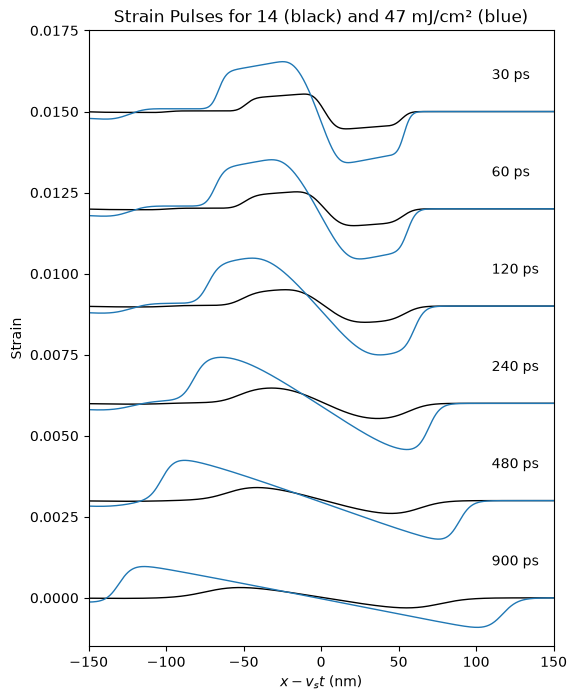

In [8]:
z = res_strains[14].quantity("distances", "nm").magnitude
delays_strain = res_strains[14].quantity("delays")

plt.figure(figsize=[6, 8])
for j, delay in enumerate([30, 60, 120, 240, 480, 900] * u.ps):
    i = np.argmin(np.abs(delays_strain - delay))
    x = z + z[40] - (v_STO * delays_strain[i]).m_as("nm")
    offset = 3e-3 * (5 - j)
    plt.plot(x, res_strains[14].strain_map[i, :] + offset, "k", lw=1)
    plt.plot(x, res_strains[47].strain_map[i, :] + offset, "C0", lw=1)
    plt.text(110, offset + 1e-3, f"{delay:~P}")
plt.xlim(-150, 150)
plt.ylim(-0.0015, 0.0175)
plt.xlabel(r"$x - v_s t$ (nm)")
plt.ylabel("Strain")
plt.title("Strain Pulses for 14 (black) and 47 mJ/cm² (blue)")
plt.show()

## Transient Reflectivity

The reflectivity of the white light between 470 and 700 nm is calculated at an angle of incidence of 45° for $\sigma$ polarization by the scalar formalism of {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>`, which calculates blocks of delays at once.
The delays are calculated in parallel with [Dask](https://docs.dask.org/en/latest/), if it is installed, e.g. by `pip install udkm1Dsim[parallel]`, see the [dynamical X-ray scattering example](#example_dynamical_xray).

In [9]:
parratt = ud.Parratt(S, True)
parratt.save_data = False
parratt.disp_messages = False
parratt.wl = np.r_[470:701:5] * u.nm
parratt.theta = np.r_[45] * u.deg
parratt.set_polarization("sigma", "none")
parratt

parameter,value
force recalc,True
cache directory,./
display messages,False
save data,False
progress bar,True
energy,1.771 eV .. 2.638 eV
wavelength,470 nm .. 700 nm
wavenumber,0.008976 1/nm .. 0.01337 1/nm
theta,45 deg .. 45 deg
q_z,0.01269 1/nm .. 0.01891 1/nm


In [10]:
res_reflectivities = {}
try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    for fluence, res_strain in res_strains.items():
        res_reflectivities[fluence] = parratt.inhomogeneous_reflectivity_transmissivity(
            res_strain, calc_type="parallel", dask_client=client
        )
    client.close()
except ImportError:
    for fluence, res_strain in res_strains.items():
        res_reflectivities[fluence] = parratt.inhomogeneous_reflectivity_transmissivity(res_strain)

Progress:   0%|          | 0/24 [00:00<?, ?it/s]

Progress:   0%|          | 0/24 [00:00<?, ?it/s]

Progress:   0%|          | 0/24 [00:00<?, ?it/s]

Progress:   0%|          | 0/24 [00:00<?, ?it/s]

2026-11-12 15:20:27,105 - distributed.worker - ERROR - Failed to communicate with scheduler during heartbeat.
Traceback (most recent call last):
  File "/home/schick/.local/share/mamba/envs/udkm1Dsim/lib/python3.12/site-packages/distributed/comm/tcp.py", line 226, in read
    frames_nosplit_nbytes_bin = await stream.read_bytes(fmt_size)
                                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tornado.iostream.StreamClosedError: Stream is closed

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "/home/schick/.local/share/mamba/envs/udkm1Dsim/lib/python3.12/site-packages/distributed/worker.py", line 1273, in heartbeat
    response = await retry_operation(
               ^^^^^^^^^^^^^^^^^^^^^^
  File "/home/schick/.local/share/mamba/envs/udkm1Dsim/lib/python3.12/site-packages/distributed/utils_comm.py", line 416, in retry_operation
    return await retry(
           ^^^^^^^^^^^^
  File "/home/schick/.local/share/mamba

The relative change of the reflectivity $\Delta R / R_0$ is calculated with respect to the reflectivity before the excitation.
As in {cite:t}`bojahr2012`, the slowly varying background, here from the expansion of the LSMO film, is subtracted by a high-pass filter.
The wave vector $k_\mathrm{P}$ of the phonons, which are probed by the wavelength $\lambda$, follows from the Brillouin backscattering condition.

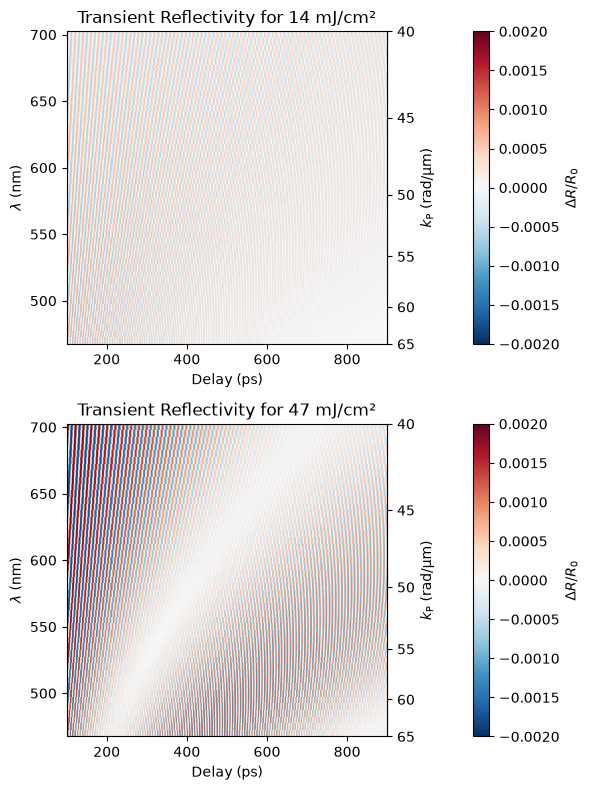

In [11]:
wl = parratt.wl.m_as("nm")
n_STO = np.real(STO.get_ref_index(parratt.wl))
cos_beta = np.sqrt(1 - (np.sin(np.radians(45)) / n_STO) ** 2)
k_P = (4 * np.pi * n_STO * cos_beta / parratt.wl).m_as("1/um")

# delays of the reflectivity, which are passed on by the strain map
t = res_reflectivities[14].quantity("delays", "ps").magnitude
dR = {}
for fluence, res_reflectivity in res_reflectivities.items():
    R = res_reflectivity.R[:, :, 0]
    dR[fluence] = R / np.mean(R[t < 0], axis=0) - 1
    dR[fluence] = dR[fluence] - gaussian_filter1d(dR[fluence], 10, axis=0)

plt.figure(figsize=[6, 8])
for j, fluence in enumerate([14, 47]):
    ax = plt.subplot(2, 1, j + 1)
    plt.pcolormesh(t, wl, dR[fluence].T, cmap="RdBu_r", vmin=-2e-3, vmax=2e-3, shading="auto")
    plt.colorbar(label=r"$\Delta R / R_0$", pad=0.18)
    plt.xlim(100, 900)
    plt.xlabel("Delay (ps)")
    plt.ylabel(r"$\lambda$ (nm)")
    secax = ax.secondary_yaxis(
        "right",
        functions=(
            lambda x: np.interp(x, wl, k_P),
            lambda k: np.interp(k, k_P[::-1], wl[::-1]),
        ),
    )
    secax.set_ylabel(r"$k_\mathrm{P}$ (rad/µm)")
    plt.title(f"Transient Reflectivity for {fluence} mJ/cm²")
plt.tight_layout()
plt.show()

All wavelengths show Brillouin oscillations, whose period increases with the wavelength.
For the highest fluence a beating is observed, see Fig. 2 of {cite:t}`bojahr2012`.
Its node marks the absence of the phonons with the according wave vector $k_\mathrm{P}$ in the strain pulse at that delay, which moves to smaller wave vectors, i.e. longer wavelengths, with time.

## Phonon Spectra

This interpretation is verified by the amplitudes of the Brillouin oscillations of each wavelength in a window of 80 ps around a delay, which are compared to the Fourier amplitudes $A(k_\mathrm{P})$ of the simulated strain profile in the STO substrate at that delay, see Fig. 4 of {cite:t}`bojahr2012`.
As the reflectivity modulations of a transparent medium scale inversely with $\lambda$ {cite:p}`thomsen1986`, $A / \lambda$ is plotted, where the wavelength $\lambda(k_\mathrm{P})$ is given by the Brillouin backscattering condition.

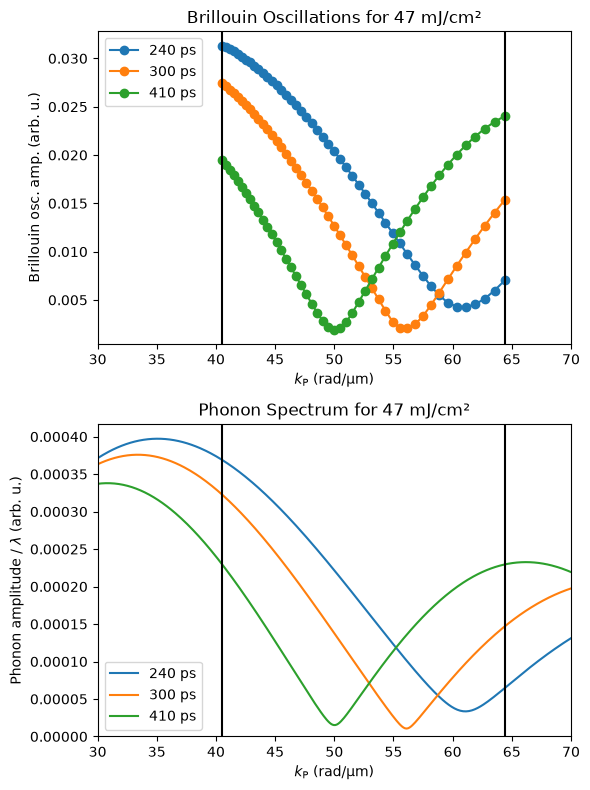

In [12]:
# Brillouin backscattering condition beyond the probed wavelengths
wl_wide = np.r_[440:1500:5] * u.nm
n_wide = np.real(STO.get_ref_index(wl_wide))
k_wide = (4 * np.pi * n_wide * np.sqrt(1 - (np.sin(np.radians(45)) / n_wide) ** 2) / wl_wide).m_as(
    "1/um"
)

window = np.hanning(81)
nfft = 4096
k = 2 * np.pi * np.fft.rfftfreq(2**17, c_STO.m_as("um"))

plt.figure(figsize=[6, 8])
for delay in [240, 300, 410]:
    i = np.argmin(np.abs(t - delay))
    # amplitude of the Brillouin oscillations in a window around the delay
    spectrum = np.abs(np.fft.rfft(dR[47][i - 40 : i + 41] * window[:, None], nfft, axis=0))
    plt.subplot(2, 1, 1)
    plt.plot(k_P, np.max(spectrum, axis=0), "o-", label=f"{delay} ps")
    # Fourier amplitude of the strain profile in the substrate
    amplitude = np.abs(np.fft.rfft(res_strains[47].strain_map[i, 93:], 2**17))
    plt.subplot(2, 1, 2)
    wavelength = np.interp(k, k_wide[::-1], wl_wide.m_as("nm")[::-1])
    plt.plot(k, amplitude / wavelength, label=f"{delay} ps")

ylabels = ["Brillouin osc. amp. (arb. u.)", "Phonon amplitude / $\\lambda$ (arb. u.)"]
for j, ylabel in enumerate(ylabels):
    plt.subplot(2, 1, j + 1)
    plt.axvline(k_P.min(), color="k")
    plt.axvline(k_P.max(), color="k")
    plt.xlim(30, 70)
    plt.xlabel(r"$k_\mathrm{P}$ (rad/µm)")
    plt.ylabel(ylabel)
    plt.legend()
plt.subplot(2, 1, 1)
plt.title("Brillouin Oscillations for 47 mJ/cm²")
plt.subplot(2, 1, 2)
plt.ylim(bottom=0)
plt.title("Phonon Spectrum for 47 mJ/cm²")
plt.tight_layout()
plt.show()

The minimum of the Brillouin oscillations moves through the window of the probed wave vectors, which is marked by the vertical lines, as the minimum of the phonon spectrum of the strain pulse.

## Sound Velocity Distribution

For the linear dispersion of the acoustic phonons, the frequency $\omega_\mathrm{P}(\lambda)$ of the Brillouin oscillations yields the sound velocity

$$
v_s = \frac{\omega_\mathrm{P}(\lambda) \lambda}{4 \pi n(\lambda) \cos\beta}.
$$

As in {cite:t}`bojahr2012`, the Fourier transforms of the Brillouin oscillations of all wavelengths are transformed to sound velocities and summed, see Fig. 3 of {cite:t}`bojahr2012`.

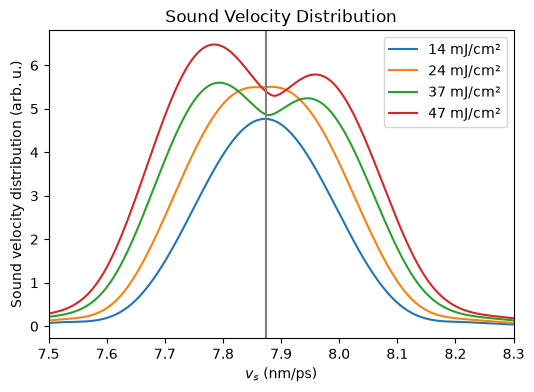

In [13]:
select = t >= 20
nfft = 2**15
frequencies = np.fft.rfftfreq(nfft, 1e-12)  # Hz
v_grid = np.r_[7.5:8.3:0.002]  # nm/ps

plt.figure(figsize=[6, 4])
for fluence in res_strains.keys():
    spectrum = np.abs(
        np.fft.rfft(dR[fluence][select] * np.hanning(np.sum(select))[:, None], nfft, axis=0)
    )
    distribution = np.zeros_like(v_grid)
    for j in range(len(wl)):
        v = frequencies * wl[j] * 1e-9 / (2 * n_STO[j] * cos_beta[j]) * 1e-3  # nm/ps
        distribution += np.interp(v_grid, v, spectrum[:, j])
    plt.plot(v_grid, distribution, label=f"{fluence:g} mJ/cm²")
plt.axvline(v_STO.m_as("nm/ps"), color="gray")
plt.xlim(7.5, 8.3)
plt.xlabel(r"$v_s$ (nm/ps)")
plt.ylabel("Sound velocity distribution (arb. u.)")
plt.legend()
plt.title("Sound Velocity Distribution")
plt.show()

For the lowest fluence, a single peak at the sound velocity of STO (gray line) is observed.
With increasing fluence, the distribution broadens and eventually splits into two peaks, as the compressive and tensile parts of the strain pulse propagate about 1 % faster and slower than the sound velocity, respectively.
The damping of the phonons reduces the amplitude of the oscillations with time, which broadens the peaks.

## Gallery Plot

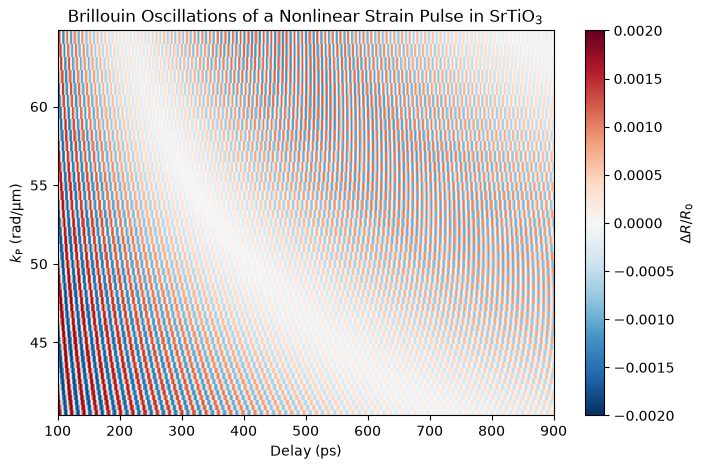

In [14]:
plt.figure(figsize=[8, 5])
plt.pcolormesh(t, k_P, dR[47].T, cmap="RdBu_r", vmin=-2e-3, vmax=2e-3, shading="auto")
plt.colorbar(label=r"$\Delta R / R_0$")
plt.xlim(100, 900)
plt.xlabel("Delay (ps)")
plt.ylabel(r"$k_\mathrm{P}$ (rad/µm)")
plt.title("Brillouin Oscillations of a Nonlinear Strain Pulse in SrTiO$_3$")
plt.show()